Visualize out of shelter runs

In [82]:
%load_ext autoreload
%autoreload 2

from behave_analysis.process.process import Process
from behave_analysis.analyze.CCA.find_shelter_exit_and_runs import find_shelter_exit_runs
from behave_analysis.analyze.filtering_data.filtering_functions import filter_video_dataframe
from behave_analysis.utils.arena_plotting import Arena
from settings.settings_analyze_efizz import Settings_ae
import matplotlib.gridspec as gridspec
from behave_analysis.analyze.EscapePattern.escape_pattern_utils import homing_escape_filtering_vector
from behave_analysis.analyze.behaviour.homings_escapes.homings_add_to_video_df import add_homie_to_video_df
from behave_analysis.analyze.EscapePattern.tuning_sig_cells import find_sig_tuned_cells_after_residual
from behave_analysis.analyze.EscapePattern.ComputeEscapeTuning import ComputeEscapeTuning
from databank import full_experiments_objects as experiments_objects
from settings.settings_overrides import settings_overrides
from behave_analysis.utils.identify_condition import build_condition_vector
from behave_analysis.analyze.EscapePattern.tuning_sig_cells import compute_tuning_stat

import numpy as np
import matplotlib.pyplot as plt
import polars as pl
import os

tuning_settings = {'ep_bins': 25,
                    'ep_no_stationary': False,
                    'ep_interpolation_mult': 2,
                    'ep_gaussian_fitting': False,
                    'ep_compute_loo_reliability': False,
                    'ep_tuned_compare_method': 'euclidean',
                    'ep_tuned_stats': 'bootstrap',
                    'ep_tuned_stats_samples': 100,
                    'linshift_min_step': 120,
                    'linshift_step': 80,
                    'linshift_step_n': 100,
                    'stim_type': 'audio',
                    'cluster_type': 'good',
                    'cluster_labels': "bombcell",
                    "homings": 'manual',
                    'condition_types': 'experimental_conditions',
                    'compartment_split': ['all'],
                    'redo_compute': False}
Settings_ae = settings_overrides(Settings_ae, tuning_settings)

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [76]:
experiments_objects[3]# 1,3, 12

Experiment(nick_name='JAL004', total_sessions=10, mouse_number_pyrat='BAA-1103424', experiment_file_names=None, root_path=WindowsPath('JAL004'), experiment_name='mushroom', experiment_idx=2, experiment_date='2023_08_22', experiment_time='13_13_41', experiment_path=WindowsPath('004_mush1_2023_08_22T13_13_41'), valid_time=[0.25, 158.26], shelter_time=[72, -1], barrier_time=[], barrier_flip_time=None)

2026-09-17 12:33:57.038 | INFO     | behave_analysis.analyze.behaviour.homings_escapes.homings:__init__:43 - checking for existing homings results
2026-09-17 12:33:57.062 | INFO     | behave_analysis.analyze.results_database_utils:check_database_for_same_run:24 - Found 4 matched results in database: ['d7df4d3da1d74343' '632de282595f4202' '1f770cdcacaf4d7b'
 'a6aec82f530e452f'] in the folder Z:\Jasmine_Laurence\Experimental_Data\JAL004\004_mush1_2023_08_22T13_13_41\processed_data\homings\Homing_database.csv
2026-09-17 12:33:57.063 | INFO     | behave_analysis.analyze.behaviour.homings_escapes.homings:get_homings:60 - Homing analysis already done with these settings, loading from database...
2026-09-17 12:33:57.076 | INFO     | behave_analysis.analyze.EscapePattern.ComputeEscapeTuning:__init__:72 - checking for existing results to frac_route in homing&escape in EP tuning database...
2026-09-17 12:33:57.116 | INFO     | behave_analysis.analyze.results_database_utils:check_database_for_sam

computing tuning in conditions: ['pre_shelter', 'shelter_present']


Text(0.5, 0.98, 'Shelter outings')

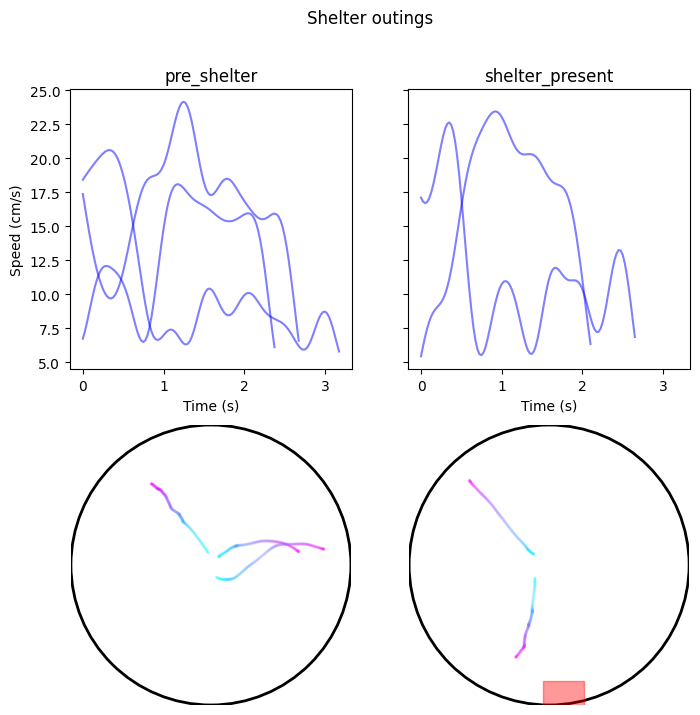

In [77]:
"""Load behavioral data"""
exp = experiments_objects[3]
session = Process(exp).load_session()
session_start = session['valid_time'][0]*60*40
video_df = pl.read_csv(os.path.join(session['base_path'], session['processed_path']) + "\\" + "full_video_dataframe.csv")
video_df = add_homie_to_video_df(session, video_df, homing_type=Settings_ae.homings)
variable = "frac_route in homing&escape"
computeET = ComputeEscapeTuning(tuning=variable, session=session, settings=Settings_ae, aefizz=None)
cond_list = computeET.ET.all_conditions

"""Visualize the runs and their speed profiles"""

cap = 20
shelter_outings = find_shelter_exit_runs(
    video_df,
    min_speed_cm_s=5.0,
    min_distance_cm=25.0,
)

fig, axs = plt.subplots(2, len(cond_list), figsize=(4*len(cond_list), 8), sharex="row", sharey="row")
for c, cond in enumerate(cond_list):
    frames_by_condition_explore = filter_video_dataframe(video_df, condition=cond, outofshelter=True, exclude_escape=True, exclude_homings=True)["frames"].to_numpy() - 1
    indices = np.array([idx for idx in np.where(shelter_outings)[0] if idx in frames_by_condition_explore])
    # plot speed traces
    Arena(ax=axs[1,c], condition=cond, 
          barrier_coordinates=session['barrier_location'][:-1] if session['barrier_location'] is not None else None, 
          full_image=False)
    start = np.concatenate([np.zeros(1), np.where(np.diff(indices) > 1)[0] + 1, np.array([len(indices)])]).astype(int)
    for s in range(len(start[:-1])):
        if s > cap:
            break
        seg = np.arange(indices[start[s]], indices[start[s+1]-1])
        time = np.arange(len(seg)) / 40.0  # Assuming 40 frames per second
        axs[0,c].plot(time, video_df["speed"].to_numpy()[seg], color = 'blue', alpha = 0.5)
        axs[0,c].set_xlabel("Time (s)")
        axs[1,c].scatter(video_df["mouse_x_position"].to_numpy()[seg], video_df["mouse_y_position"].to_numpy()[seg], 
                         c = np.linspace(0, 1, len(seg)) if len(seg) > 1 else np.array([0.0]), cmap = "cool",
                         s=2, alpha = 0.2, label = "Out of shelter runs" if s == 0 else None)
    axs[0,c].set_title(f"{cond_list[c]}")
axs[0,0].set_ylabel("Speed (cm/s)")
fig.suptitle("Shelter outings")

Visualize neural activity in bout runs

In [78]:
"""Load neural data"""
fcm = np.load(os.path.join(session['base_path'], session['processed_path']) + "\\" + "frame_by_good_cluster_matrix_bc.npy")
mean_fcm = np.nanmean(fcm, axis=0)
std_fcm = np.nanstd(fcm, axis=0)
fcm_z = (fcm - mean_fcm) / std_fcm

In [81]:
"""Load tuning data"""

variable = "frac_route in homing&escape"
vars_to_subtract = ["speed in explore", "bird_dist_shelter in explore", "2D_position in explore"]
sig_cells_dict = find_sig_tuned_cells_after_residual(session, Settings_ae, variable, vars_to_subtract, remove_hdir = True, stat="zscore_peak")

computeET = ComputeEscapeTuning(tuning=variable, session=session, settings=Settings_ae, aefizz=None)
ep_data = computeET.load_results()

2026-09-17 12:34:38.367 | INFO     | behave_analysis.analyze.EscapePattern.ComputeEscapeTuning:__init__:72 - checking for existing results to frac_route in homing&escape in EP tuning database...
2026-09-17 12:34:38.387 | INFO     | behave_analysis.analyze.results_database_utils:check_database_for_same_run:24 - Found 1 matched results in database: ['43088b232cce4797'] in the folder Z:\Jasmine_Laurence\Experimental_Data\JAL004\004_mush1_2023_08_22T13_13_41\processed_data\models\escape_tuning\EscapePattern_results.csv


computing tuning in conditions: ['pre_shelter', 'shelter_present']


no barrier in this session
barrier was not flipped in this session


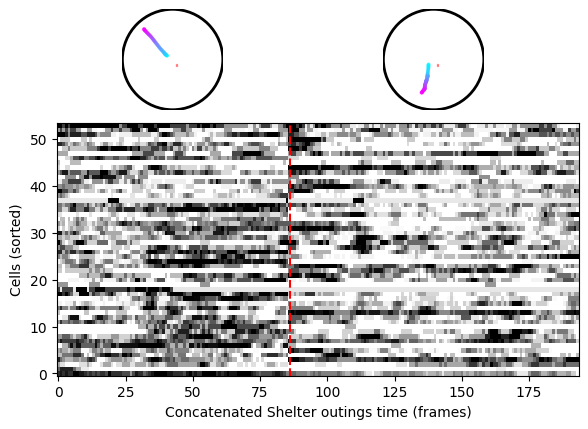

In [90]:
# Figure layout tuned to the heatmap width: each arena sits above its own heatmap segment.
# This version uses the same proportional-width + arena placement approach as the sequence heatmap notebook.
bool_name = "Shelter outings"
# bool_name = "homing"
cond_idx = 1
cond = computeET.ET.all_conditions[cond_idx]
cap = 10
# sig_cells = sig_cells_dict[cond]
real_stat, shift_stat = compute_tuning_stat(stat='zscore_peak', 
                                            shifted_matrix=ep_data['fr_shift'], 
                                            shift0=int(np.shape(ep_data['fr_shift'])[0] / 2), 
                                            neural_matrix=ep_data['neural_matrix'], 
                                            condition=ep_data['condition_vector'])
sig_cells = real_stat > np.nanpercentile(shift_stat, 95, axis=0)
sig_cells = sig_cells[cond_idx,:]

if "homing" in bool_name:
    indices = (np.where(ep_data['homing_vector'])[0]/2).astype(int)
    condition = ep_data['condition_vector']
else:
    indices = np.where(shelter_outings)[0]
    condition = build_condition_vector(session = session,
                                                n_frames=len(shelter_outings),
                                                fps=session["video"]["fps"],
                                                condition_list=computeET.ET.all_conditions)
    condition = condition[indices]

tuning_hm = ep_data['fr_full'][cond_idx, sig_cells, :]
tuning_hm = np.divide(tuning_hm - mean_fcm[sig_cells, np.newaxis],
                        std_fcm[sig_cells, np.newaxis],
                        out=np.zeros_like(tuning_hm, dtype=np.float64),
                        where=std_fcm[sig_cells, np.newaxis] != 0)
sort_idx = np.argsort(np.nanargmax(tuning_hm, axis=1))
indices_this_cond = indices[condition == cond_idx]
starts = np.concatenate(([0], np.where(np.diff(indices_this_cond) > 1)[0] + 1))
ends = np.concatenate((starts[1:], [len(indices_this_cond)]))
# optionally cap number of bouts
# if cap is not None:
#     starts = starts[:cap]
#     ends = ends[:cap]
# starts = starts[5:10]
# ends = ends[5:10]
# Reuse the bout segmentation already computed in the prior cell
chunks = [indices_this_cond[s:e] for s, e in zip(starts, ends)]
durations = np.array([len(chunk) for chunk in chunks], dtype=int)
total_w = int(np.sum(durations))
max_frames = total_w

fig_left, fig_right = 0.08, 0.95
fig_top, fig_bottom = 0.97, 0.04
full_w = fig_right - fig_left
pair_h = (fig_top - fig_bottom) / 2
arena_h = pair_h * 0.30
hm_h = pair_h * 0.68
gap_h = pair_h * 0.02

fig = plt.figure(figsize=(max(6, total_w / 100), 8))
prop_w = (total_w / max_frames) * full_w

# heatmap axis
ax_hm = fig.add_axes([fig_left, fig_bottom, prop_w, hm_h])
heatmap = np.concatenate([fcm_z[chunk, :][:, sig_cells].T for chunk in chunks], axis=1)
# keep cell ordering aligned with the displayed bouts
if len(sort_idx) > 0:
    heatmap = np.concatenate([
        fcm_z[chunk, :][:, sig_cells][:, sort_idx].T for chunk in chunks
    ], axis=1)

ax_hm.imshow(
    heatmap,
    aspect='auto',
    origin='lower',
    cmap='gray_r',
    vmin=-0.5,
    vmax=2,
    interpolation='none'
)

boundary_x = np.cumsum(durations)[:-1]
for x in boundary_x:
    ax_hm.axvline(x=x, color='red', linestyle='--', linewidth=1.5)

ax_hm.set_xlabel(f'Concatenated {bool_name} time (frames)')
ax_hm.set_ylabel('Cells (sorted)')

# Arena placement above the heatmap segments
fig_w, fig_h = fig.get_size_inches()
interval_starts = np.concatenate(([0], np.cumsum(durations[:-1])))
interval_centers = interval_starts + durations / 2.0
min_dur = np.min(durations)

arena_bottom = fig_bottom + hm_h + gap_h
side_from_data_in = (prop_w * (min_dur / total_w) * 0.9) * fig_w
max_side_arena_in = (arena_h * 0.90) * fig_h
max_side_abs_in = 1.6
side_in = min(side_from_data_in, max_side_arena_in, max_side_abs_in)

top_w = side_in / fig_w
top_h = side_in / fig_h
top_y = arena_bottom + (arena_h - top_h) / 2.0

for frames, c_mid in zip(chunks, interval_centers):
    cx = fig_left + (c_mid / total_w) * prop_w
    left = np.clip(cx - top_w / 2.0, fig_left, fig_left + prop_w - top_w)

    ax_xy = fig.add_axes([left, top_y, top_w, top_h])
    Arena(
        ax=ax_xy,
        condition=cond,
        barrier_coordinates=session['barrier_location'][:-1] if session['barrier_location'] is not None else None,
        shelter_coordinates=session['shelter_location'] if session['shelter_location'] is not None else None,
        full_image=False
    )

    prog = np.linspace(0, 1, len(frames)) if len(frames) > 1 else np.array([0.0])
    ax_xy.scatter(
        video_df['mouse_x_position'].to_numpy()[frames],
        video_df['mouse_y_position'].to_numpy()[frames],
        c=prog,
        cmap='cool',
        vmin=0,
        vmax=1,
        s=3,
        alpha=0.35
    )
    ax_xy.set_xticks([])
    ax_xy.set_yticks([])

plt.show()